In [1]:
from tkinter import Tk, filedialog

# Install only if needed
%pip install -q landingai pillow matplotlib gTTS

# Clean up stale Tk state from earlier notebook cells
try:
    if "root" in globals() and root is not None:
        root.update()
        root.destroy()
except Exception:
    pass


root = Tk()
root.withdraw()
root.attributes("-topmost", True)

file_paths = filedialog.askopenfilenames(
    title="Select Medicine Images",
    filetypes=[("Image files", "*.jpg *.jpeg *.png *.bmp")]
)

root.destroy()

print("Selected files:", file_paths)
print("Type:", type(file_paths))

Note: you may need to restart the kernel to use updated packages.
Selected files: ('C:/Users/ARNAV/Downloads/emotion-predictor/images sad5.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images sad8.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images sad7.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images7.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images8.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images neutral7.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images neutral6.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images neutral5.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images neutral4.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images sad4.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images sad2.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images5.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images4.jpg', 'C:/Users/ARNAV/Downloads/emotion-predictor/images3.jpg')
Type: <class 'tuple'>


In [2]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Test Pillow's JPEG encoder independently of LandingAI
buffer = io.BytesIO()
test_image = Image.new("RGB", (10, 10), color="red")
test_image.save(buffer, format="JPEG")

print("JPEG encoding successful:", len(buffer.getvalue()), "bytes")

Pillow version: 10.4.0
JPEG encoding successful: 633 bytes


## Medicine Bottles

In [ ]:

import os
from getpass import getpass
from landingai.predict import Predictor

API_KEY = getpass("Enter your LandingAI API Key: ")

ENDPOINT_ID = "85e351ec-877a-4a1d-9d45-d3aa2c3cf93d"
c29jbG8xd3pxcG42ZHhza3p1YnEzOmZ2dUNpaXlneDlBUzNPOEw0cWE5R1RBcHpjUFNpVVpY

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized successfully.")

In [3]:
%pip install pillow numpy ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [4]:
from tkinter import Tk, filedialog
from PIL import Image
import numpy as np

root = Tk()
root.withdraw()
root.attributes('-topmost', True)

file_paths = filedialog.askopenfilenames(
    title="Select Medicine Images",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

print("Total images selected:", len(file_paths))

Total images selected: 0


In [ ]:
images = {}

for path in file_paths:

    filename = path.split("/")[-1]

    image = Image.open(path).convert("RGB")

    image_array = np.array(image)

    images[filename] = {
        "image": image,
        "array": image_array
    }

    print("\nFilename:", filename)
    print("Image size:", image.size)
    print("Image array shape:", image_array.shape)

    display(image)

print("\nTotal images processed:", len(images))

In [ ]:
all_predictions = {}

for filename, data in images.items():

    image_array = data["array"]

    predictions = predictor.predict(image_array)

    all_predictions[filename] = predictions

    print()
    print("Image:", filename)
    print("Prediction count:", len(predictions))

    for i, prediction in enumerate(predictions, start=1):
        print(f"\nPrediction {i}:")
        print(prediction)

print("\nPredictions completed for all images!")

In [ ]:
!pip install pillow numpy gtts ipython landingai

In [ ]:
from tkinter import Tk, filedialog
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io
import os

def medicine_assistant():

    print("Medicine Label Cognitive Assistant")
    print("Upload medicine bottle images for analysis.")

 

    root = Tk()
    root.withdraw()
    root.attributes('-topmost', True)

    file_paths = filedialog.askopenfilenames(
        title="Select Medicine Images",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp")
        ]
    )

    root.destroy()

    if not file_paths:
        print("No images uploaded.")
        return

   
    for path in file_paths:

        filename = os.path.basename(path)

        print("\n" + "="*50)
        print("Analyzing:", filename)

        image = Image.open(path).convert("RGB")

        display(image)

        image_array = np.array(image)

     

        try:
            predictions = predictor.predict(image_array)

        except Exception as e:
            print("Prediction failed:", e)
            continue

        print("\nRaw model predictions:")
        print(predictions)

        if not predictions:
            print("No predictions returned by the model.")
            continue

   

        result = "Medicine label analysis completed."

        print("\nDetection Results:")

        for i, prediction in enumerate(predictions, start=1):

            print(f"\nPrediction {i}:")
            print(prediction)
   
 

        display(Markdown(
            f"### Medicine Assistant Response\n"
            f"**Image:** {filename}\n\n"
            f"**Status:** {result}"
        ))

     

        speech = gTTS(
            text=f"Medicine image analysis completed for {filename}. "
                 "Please review the displayed detection results.",
            lang="en"
        )

        audio_filename = "medicine_response.mp3"

        speech.save(audio_filename)

        display(Audio(audio_filename, autoplay=False))

    print("\nMedicine analysis completed for all uploaded images!")


medicine_assistant()

## Emotions

In [ ]:

import os
from getpass import getpass
from landingai.predict import Predictor

API_KEY = getpass("Enter your LandingAI API Key: ")

ENDPOINT_ID = "8b59b5a1-9138-4a59-8eca-df90a1de1972"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized successfully.")

In [5]:
from tkinter import Tk, filedialog
from PIL import Image
import numpy as np

root = Tk()
root.withdraw()
root.attributes('-topmost', True)

file_path = filedialog.askopenfilenames(
    title="Select Expression Images",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

print("Total images selected:", len(file_path))

Total images selected: 14



Filename: images sad5.jpg
Image size: (320, 240)
Image array shape: (240, 320, 3)


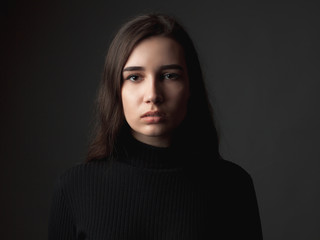


Filename: images sad8.jpg
Image size: (240, 240)
Image array shape: (240, 240, 3)


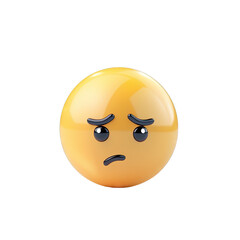


Filename: images sad7.jpg
Image size: (430, 240)
Image array shape: (240, 430, 3)


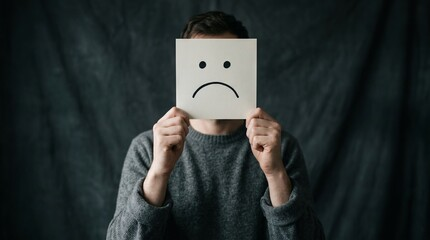


Filename: images7.jpg
Image size: (360, 240)
Image array shape: (240, 360, 3)


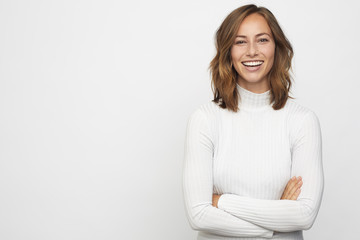


Filename: images8.jpg
Image size: (360, 240)
Image array shape: (240, 360, 3)


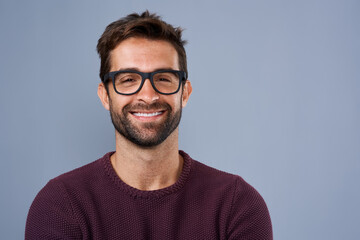


Filename: images neutral7.jpg
Image size: (360, 240)
Image array shape: (240, 360, 3)


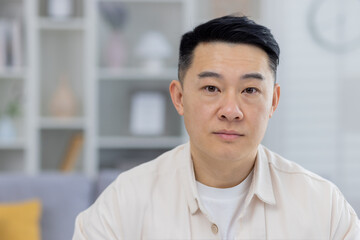


Filename: images neutral6.jpg
Image size: (343, 240)
Image array shape: (240, 343, 3)


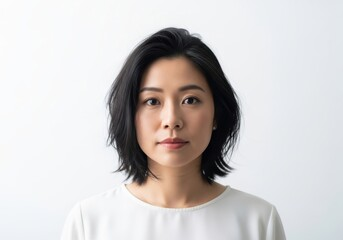


Filename: images neutral5.jpg
Image size: (360, 240)
Image array shape: (240, 360, 3)


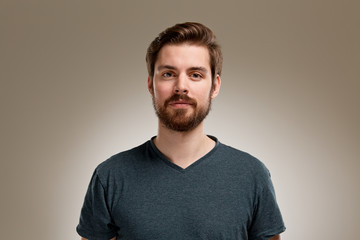


Filename: images neutral4.jpg
Image size: (430, 240)
Image array shape: (240, 430, 3)


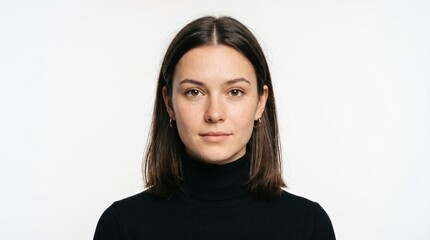


Filename: images sad4.jpg
Image size: (599, 470)
Image array shape: (470, 599, 3)


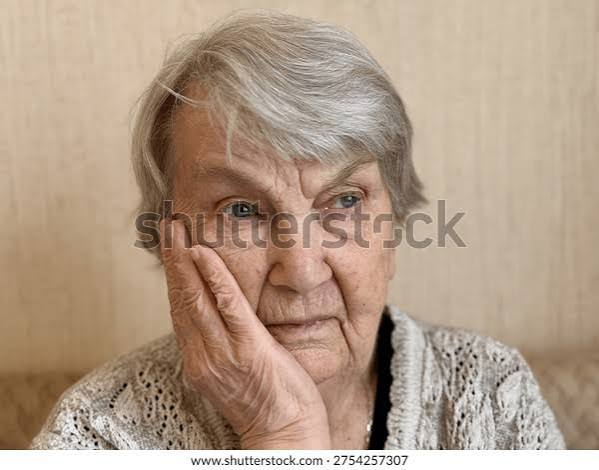


Filename: images sad2.jpg
Image size: (360, 360)
Image array shape: (360, 360, 3)


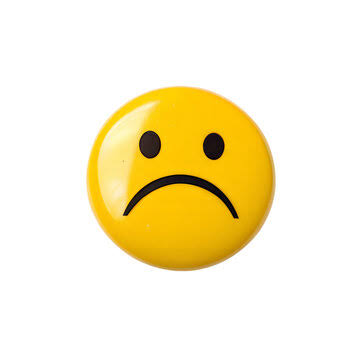


Filename: images5.jpg
Image size: (519, 385)
Image array shape: (385, 519, 3)


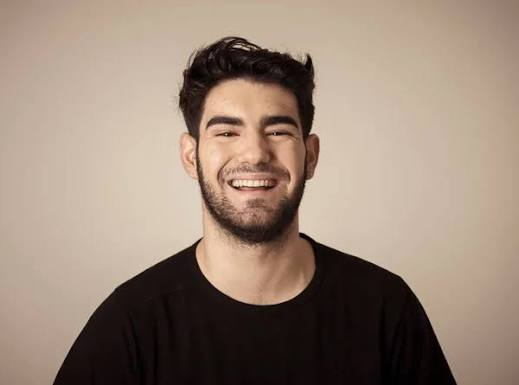


Filename: images4.jpg
Image size: (678, 452)
Image array shape: (452, 678, 3)


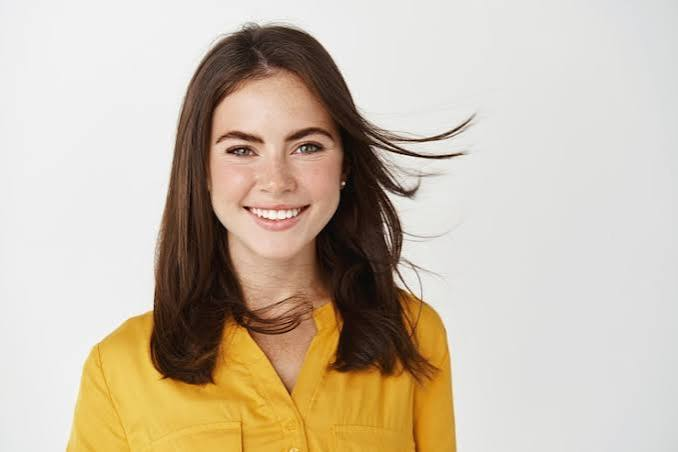


Filename: images3.jpg
Image size: (678, 452)
Image array shape: (452, 678, 3)


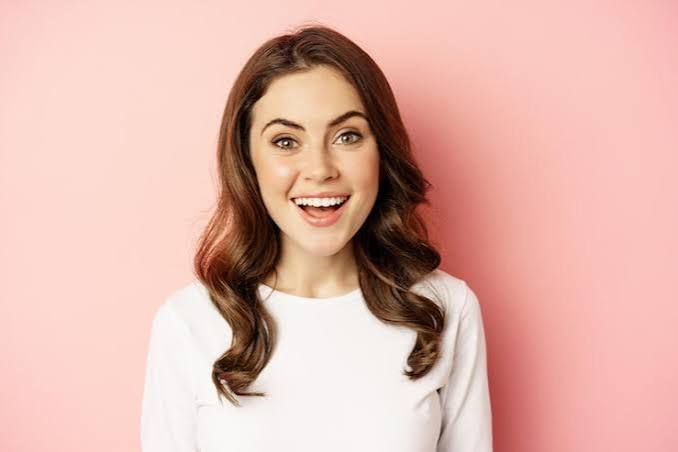


Total images processed: 14


In [6]:
images = {}

for path in file_path:

    filename = path.split("/")[-1]

    image = Image.open(path).convert("RGB")

    image_array = np.array(image)

    images[filename] = {
        "image": image,
        "array": image_array
    }

    print("\nFilename:", filename)
    print("Image size:", image.size)
    print("Image array shape:", image_array.shape)

    display(image)

print("\nTotal images processed:", len(images))

In [ ]:
all_predictions = {}

for filename, data in images.items():

    image_array = data["array"]

    predictions = predictor.predict(image_array)

    all_predictions[filename] = predictions

    print()
    print("Image:", filename)
    print("Prediction count:", len(predictions))

    for i, prediction in enumerate(predictions, start=1):
        print(f"\nPrediction {i}:")
        print(prediction)

print("\nPredictions completed for all images!")

In [ ]:
!pip install pillow numpy gtts ipython landingai

In [ ]:
from tkinter import Tk, filedialog
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io
import os

def expression_assistant():

    print("Facial Expressions Cognitive Assistant")
    print("Upload facial expression images for analysis.")

 

    root = Tk()
    root.withdraw()
    root.attributes('-topmost', True)

    file_path = filedialog.askopenfilenames(
        title="Select Expression Images",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp")
        ]
    )

    root.destroy()

    if not file_path:
        print("No images uploaded.")
        return

   
    for path in file_path:

        file = os.path.basename(path)

        print("\n" + "="*50)
        print("Analyzing:", file)

        im = Image.open(path).convert("RGB")

        display(im)

        im_array = np.array(im)

     

        try:
            prediction = predictor.predict(im_array)

        except Exception as e:
            print("Prediction failed:", e)
            continue

        print("\nRaw model predictions:")
        print(prediction)

        if not prediction:
            print("No predictions returned by the model.")
            continue

   

        result = "Facial Expression analysis completed."

        print("\nDetection Results:")

        for i, pred in enumerate(prediction, start=1):

            print(f"\nPrediction {i}:")
            print(pred)
   
 

        display(Markdown(
            f"### Facial Expressions Response\n"
            f"**Image:** {file}\n\n"
            f"**Status:** {result}"
        ))

     

        speech = gTTS(
            text=f"Facial Expressions image analysis completed for {file}. "
                 "Please review the displayed detection results.",
            lang="en"
        )

        audio_filename = "expression_response.mp3"

        speech.save(audio_filename)

        display(Audio(audio_filename, autoplay=False))

    print("\nFacial Expressions analysis completed for all uploaded images!")


expression_assistant()